# DJI Flight Data Visualizations
This notebook contains 12 different visualizations of the DJI drone flight record data.

In [1]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load the CSV file (skip the first row which contains 'sep=,')
df = pd.read_csv('DJIFlightRecord_2019-03-28_[18-46-27].csv', skiprows=1)

# Display basic info
print(f"Dataset shape: {df.shape}")
print(f"\nColumns available: {len(df.columns)}")
print(df.columns.tolist()[:20])  # Show first 20 columns

Dataset shape: (9344, 193)

Columns available: 193
['CUSTOM.date [local]', 'CUSTOM.updateTime [local]', 'OSD.flyTime', 'OSD.flyTime [s]', 'OSD.latitude', 'OSD.longitude', 'OSD.height [ft]', 'OSD.heightMax [ft]', 'OSD.vpsHeight [ft]', 'OSD.altitude [ft]', 'OSD.mileage [ft]', 'OSD.hSpeed [MPH]', 'OSD.hSpeedMax [MPH]', 'OSD.xSpeed [MPH]', 'OSD.xSpeedMax [MPH]', 'OSD.ySpeed [MPH]', 'OSD.ySpeedMax [MPH]', 'OSD.zSpeed [MPH]', 'OSD.zSpeedMax [MPH]', 'OSD.pitch']


/var/folders/0j/jrk4ghtd6wqfsm3km6pbbyn80000gn/T/ipykernel_92312/311182036.py:7: DtypeWarning: Columns (30,191) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('DJIFlightRecord_2019-03-28_[18-46-27].csv', skiprows=1)


## 1. Altitude Over Time
Shows how the drone's altitude changed throughout the flight.

/var/folders/0j/jrk4ghtd6wqfsm3km6pbbyn80000gn/T/ipykernel_92312/2381779057.py:8: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/calebstone/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128641 (\N{HELICOPTER}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


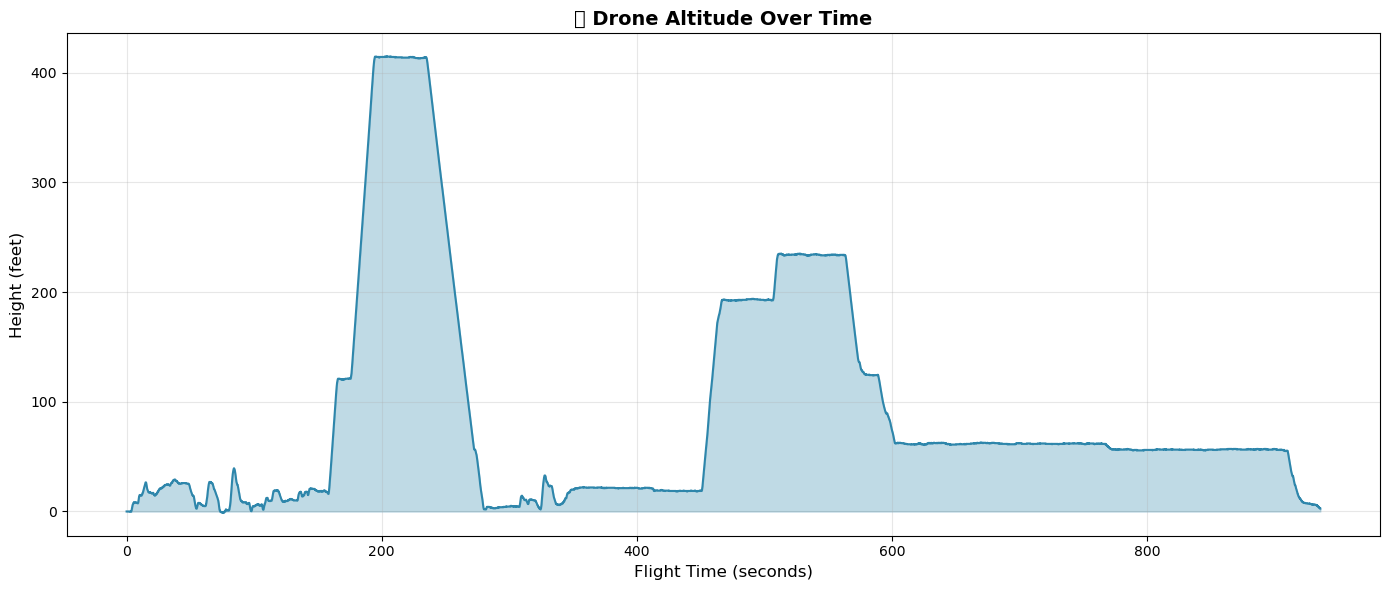

In [2]:
plt.figure(figsize=(14, 6))
plt.plot(df['OSD.flyTime [s]'], df['OSD.height [ft]'], color='#2E86AB', linewidth=1.5)
plt.fill_between(df['OSD.flyTime [s]'], df['OSD.height [ft]'], alpha=0.3, color='#2E86AB')
plt.xlabel('Flight Time (seconds)', fontsize=12)
plt.ylabel('Height (feet)', fontsize=12)
plt.title('🚁 Drone Altitude Over Time', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Horizontal Speed Over Time
Visualizes the drone's horizontal speed throughout the flight.

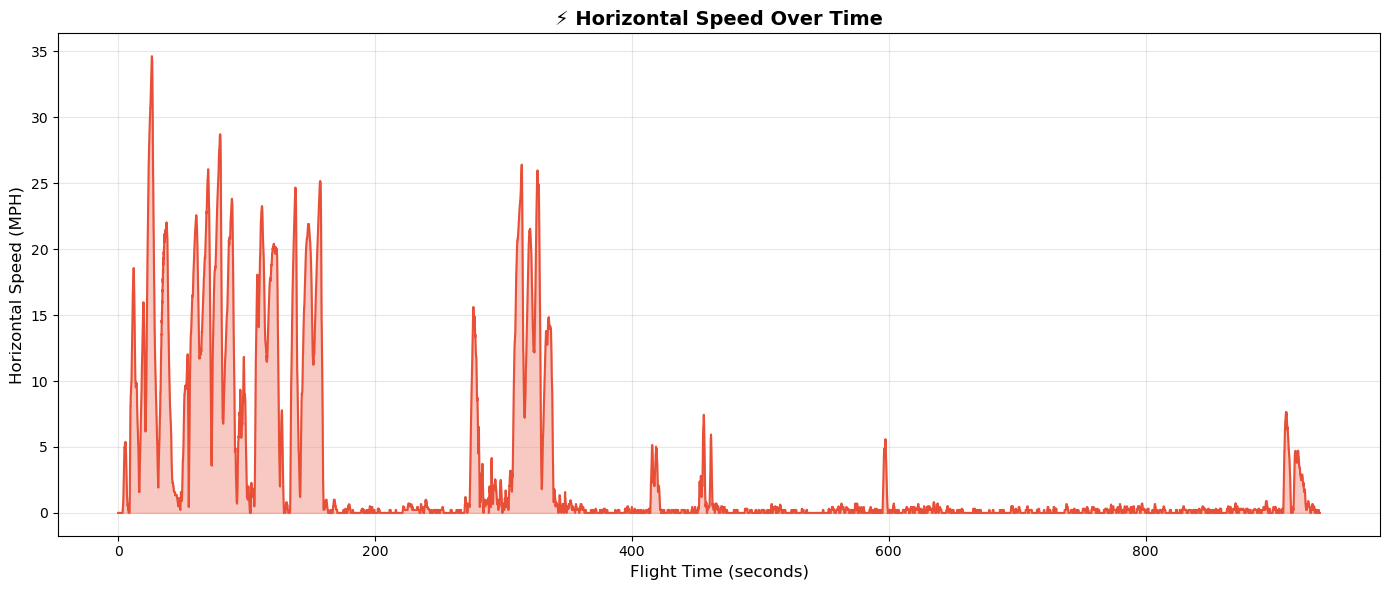

In [3]:
plt.figure(figsize=(14, 6))
plt.plot(df['OSD.flyTime [s]'], df['OSD.hSpeed [MPH]'], color='#E94F37', linewidth=1.5)
plt.fill_between(df['OSD.flyTime [s]'], df['OSD.hSpeed [MPH]'], alpha=0.3, color='#E94F37')
plt.xlabel('Flight Time (seconds)', fontsize=12)
plt.ylabel('Horizontal Speed (MPH)', fontsize=12)
plt.title('⚡ Horizontal Speed Over Time', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3. GPS Flight Path (2D Map)
Shows the drone's flight path using GPS coordinates.

/var/folders/0j/jrk4ghtd6wqfsm3km6pbbyn80000gn/T/ipykernel_92312/1443505290.py:12: UserWarning: Glyph 128506 (\N{WORLD MAP}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/calebstone/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128506 (\N{WORLD MAP}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


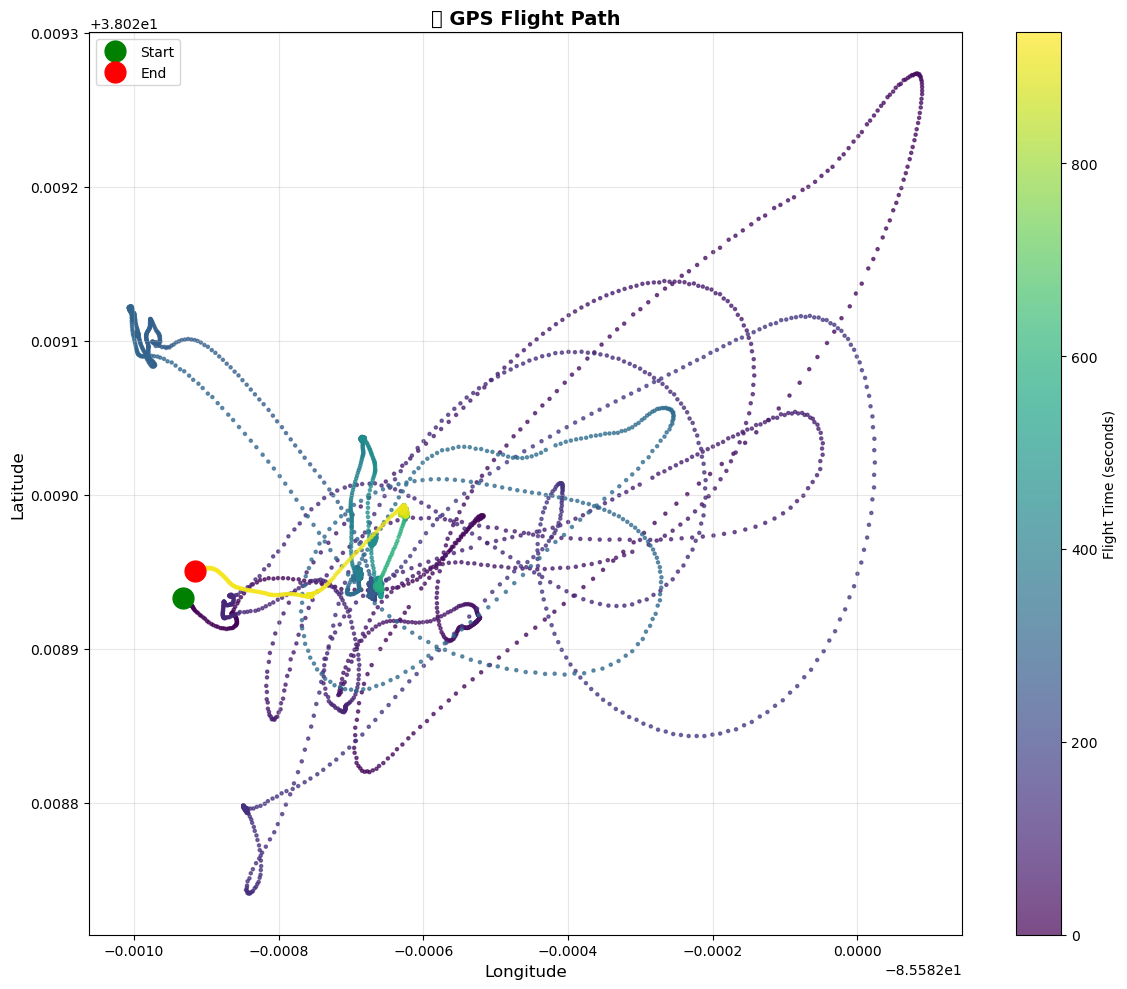

In [4]:
plt.figure(figsize=(12, 10))
scatter = plt.scatter(df['OSD.longitude'], df['OSD.latitude'], 
                     c=df['OSD.flyTime [s]'], cmap='viridis', s=5, alpha=0.7)
plt.colorbar(scatter, label='Flight Time (seconds)')
plt.plot(df['OSD.longitude'].iloc[0], df['OSD.latitude'].iloc[0], 'go', markersize=15, label='Start')
plt.plot(df['OSD.longitude'].iloc[-1], df['OSD.latitude'].iloc[-1], 'ro', markersize=15, label='End')
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.title('🗺️ GPS Flight Path', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Battery Charge Level Over Time
Tracks how the battery depleted during the flight.

/var/folders/0j/jrk4ghtd6wqfsm3km6pbbyn80000gn/T/ipykernel_92312/949413684.py:15: UserWarning: Glyph 128267 (\N{BATTERY}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/calebstone/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128267 (\N{BATTERY}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


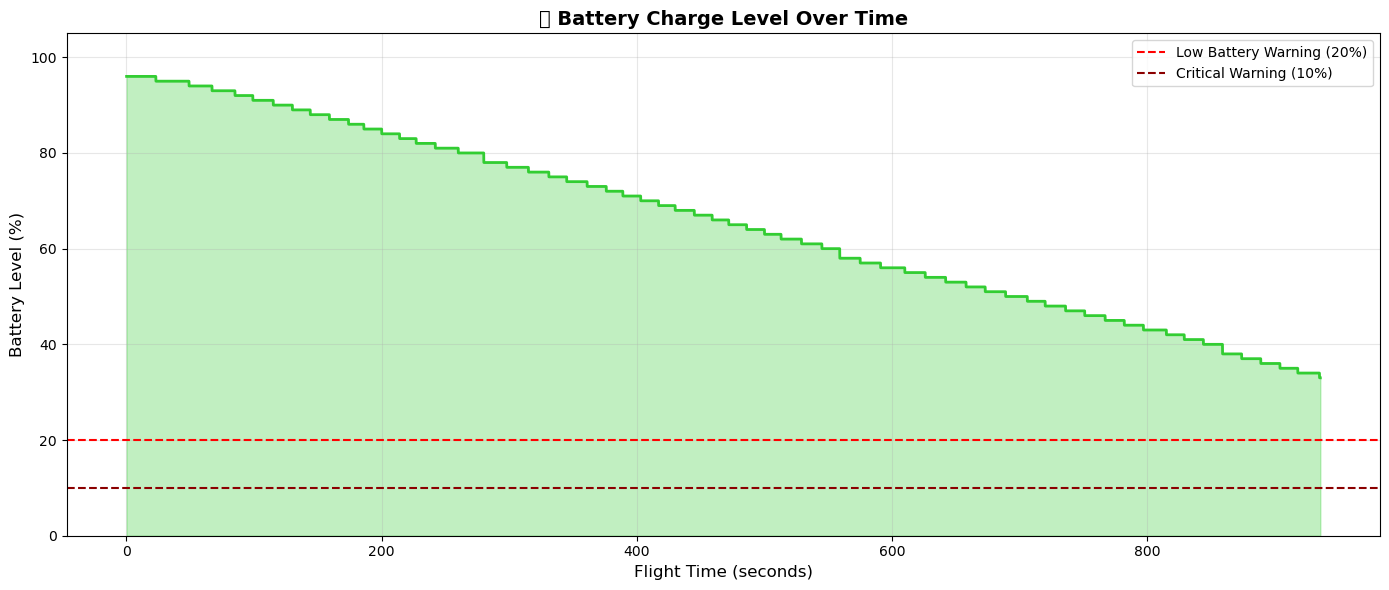

In [5]:
# Convert to numeric, handling any non-numeric values
battery_level = pd.to_numeric(df['BATTERY.chargeLevel'], errors='coerce')

plt.figure(figsize=(14, 6))
plt.plot(df['OSD.flyTime [s]'], battery_level, color='#32CD32', linewidth=2)
plt.fill_between(df['OSD.flyTime [s]'], battery_level, alpha=0.3, color='#32CD32')
plt.axhline(y=20, color='red', linestyle='--', label='Low Battery Warning (20%)')
plt.axhline(y=10, color='darkred', linestyle='--', label='Critical Warning (10%)')
plt.xlabel('Flight Time (seconds)', fontsize=12)
plt.ylabel('Battery Level (%)', fontsize=12)
plt.title('🔋 Battery Charge Level Over Time', fontsize=14, fontweight='bold')
plt.ylim(0, 105)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. 3D Flight Trajectory
A 3D visualization showing longitude, latitude, and altitude.

/var/folders/0j/jrk4ghtd6wqfsm3km6pbbyn80000gn/T/ipykernel_92312/2428234526.py:21: UserWarning: Glyph 128745 (\N{SMALL AIRPLANE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/calebstone/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128745 (\N{SMALL AIRPLANE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


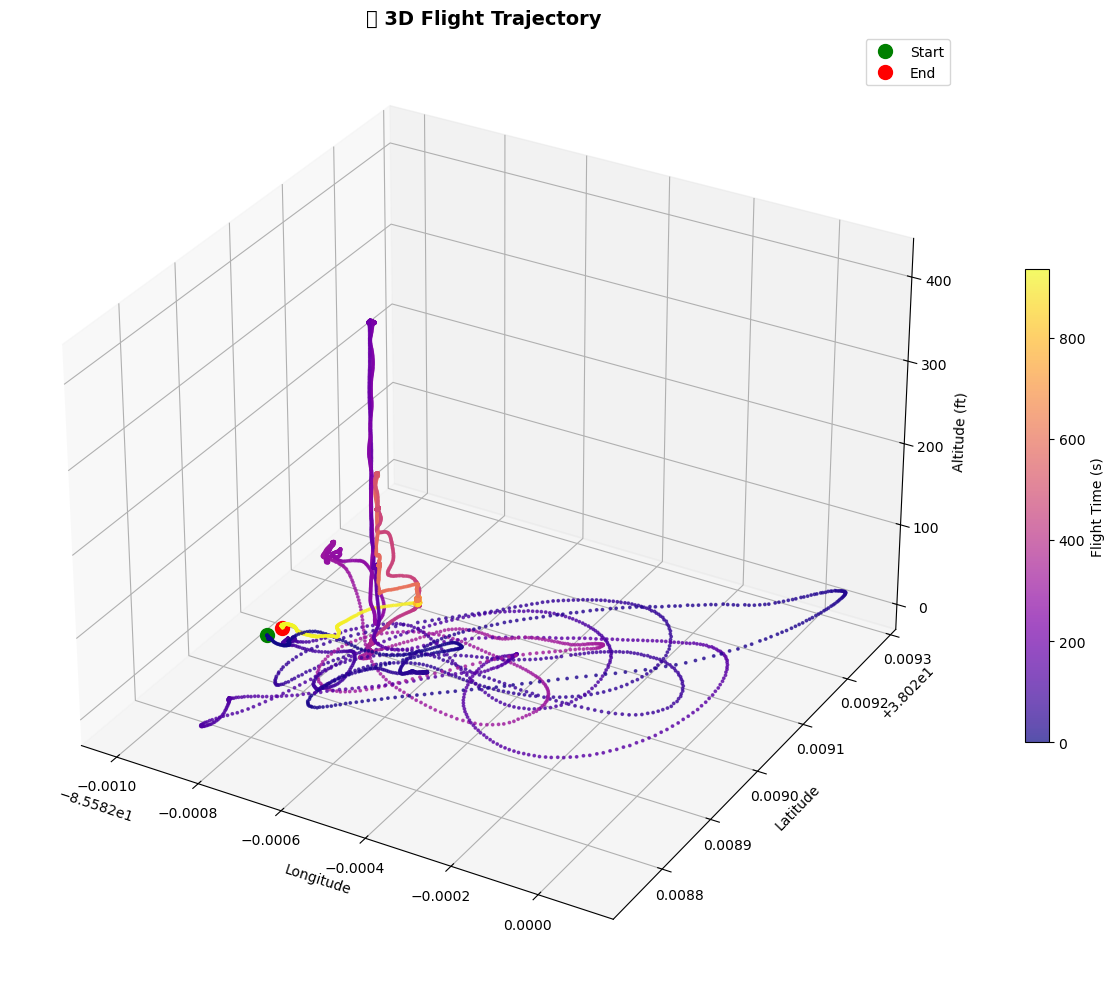

In [6]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection='3d')

# Normalize coordinates for better visualization
lon = df['OSD.longitude']
lat = df['OSD.latitude']
alt = pd.to_numeric(df['OSD.height [ft]'], errors='coerce')

scatter = ax.scatter(lon, lat, alt, c=df['OSD.flyTime [s]'], cmap='plasma', s=3, alpha=0.7)
ax.plot(lon.iloc[0:1], lat.iloc[0:1], alt.iloc[0:1], 'go', markersize=10, label='Start')
ax.plot(lon.iloc[-1:], lat.iloc[-1:], alt.iloc[-1:], 'ro', markersize=10, label='End')

ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_zlabel('Altitude (ft)')
ax.set_title('🛩️ 3D Flight Trajectory', fontsize=14, fontweight='bold')
plt.colorbar(scatter, label='Flight Time (s)', shrink=0.5)
ax.legend()
plt.tight_layout()
plt.show()

## 6. Gimbal Pitch and Roll Over Time
Shows the camera gimbal orientation throughout the flight.

/var/folders/0j/jrk4ghtd6wqfsm3km6pbbyn80000gn/T/ipykernel_92312/945979080.py:18: UserWarning: Glyph 128247 (\N{CAMERA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/calebstone/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128247 (\N{CAMERA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


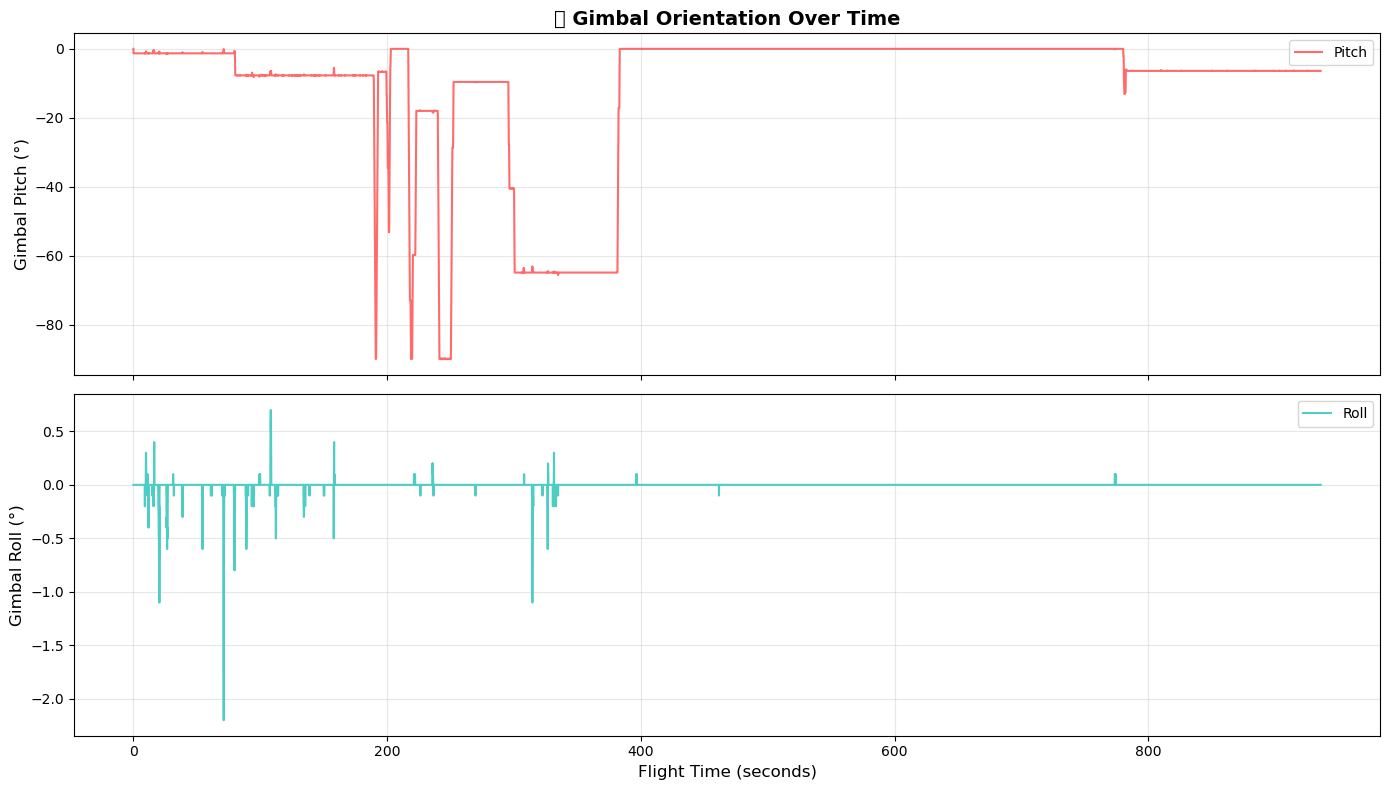

In [7]:
gimbal_pitch = pd.to_numeric(df['GIMBAL.pitch'], errors='coerce')
gimbal_roll = pd.to_numeric(df['GIMBAL.roll'], errors='coerce')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

ax1.plot(df['OSD.flyTime [s]'], gimbal_pitch, color='#FF6B6B', linewidth=1.5, label='Pitch')
ax1.set_ylabel('Gimbal Pitch (°)', fontsize=12)
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)
ax1.set_title('📷 Gimbal Orientation Over Time', fontsize=14, fontweight='bold')

ax2.plot(df['OSD.flyTime [s]'], gimbal_roll, color='#4ECDC4', linewidth=1.5, label='Roll')
ax2.set_xlabel('Flight Time (seconds)', fontsize=12)
ax2.set_ylabel('Gimbal Roll (°)', fontsize=12)
ax2.legend(loc='upper right')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Distance from Home Over Time
Tracks how far the drone traveled from its home point.

/var/folders/0j/jrk4ghtd6wqfsm3km6pbbyn80000gn/T/ipykernel_92312/1221530915.py:10: UserWarning: Glyph 127968 (\N{HOUSE BUILDING}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/calebstone/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127968 (\N{HOUSE BUILDING}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


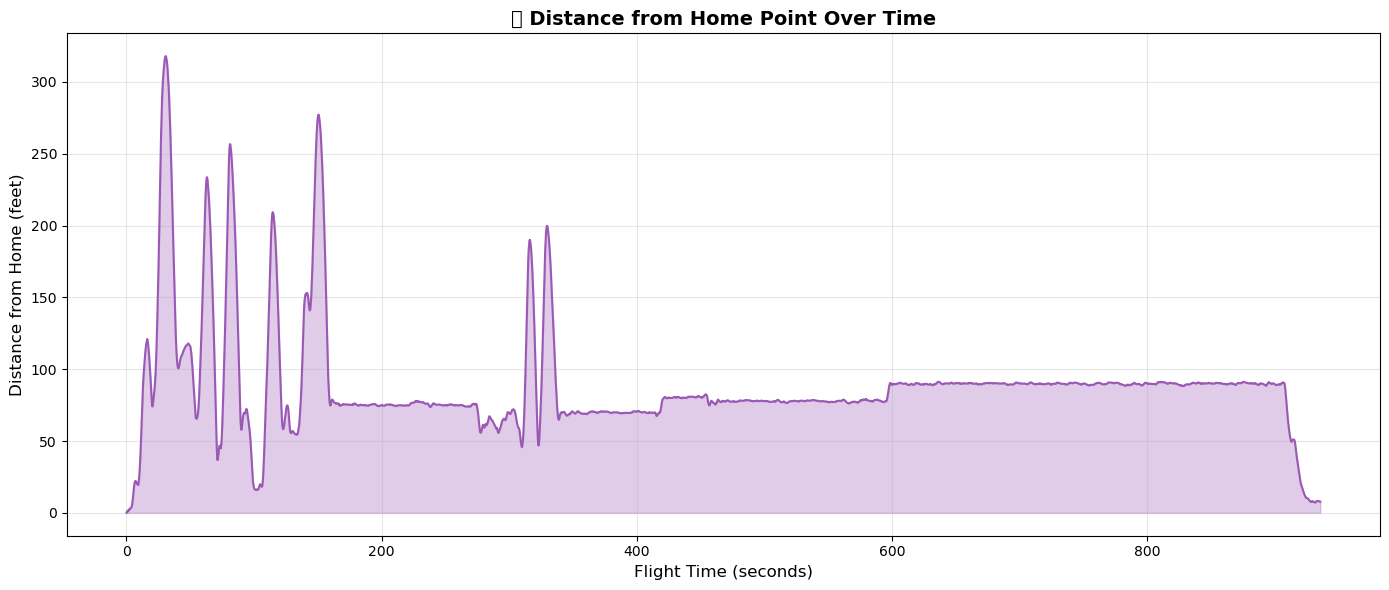

In [8]:
distance = pd.to_numeric(df['HOME.distance [ft]'], errors='coerce')

plt.figure(figsize=(14, 6))
plt.plot(df['OSD.flyTime [s]'], distance, color='#9B59B6', linewidth=1.5)
plt.fill_between(df['OSD.flyTime [s]'], distance, alpha=0.3, color='#9B59B6')
plt.xlabel('Flight Time (seconds)', fontsize=12)
plt.ylabel('Distance from Home (feet)', fontsize=12)
plt.title('🏠 Distance from Home Point Over Time', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. RC Signal Strength (Uplink vs Downlink)
Compares the remote controller signal strength for both directions.

/var/folders/0j/jrk4ghtd6wqfsm3km6pbbyn80000gn/T/ipykernel_92312/407384960.py:12: UserWarning: Glyph 128246 (\N{ANTENNA WITH BARS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/calebstone/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128246 (\N{ANTENNA WITH BARS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


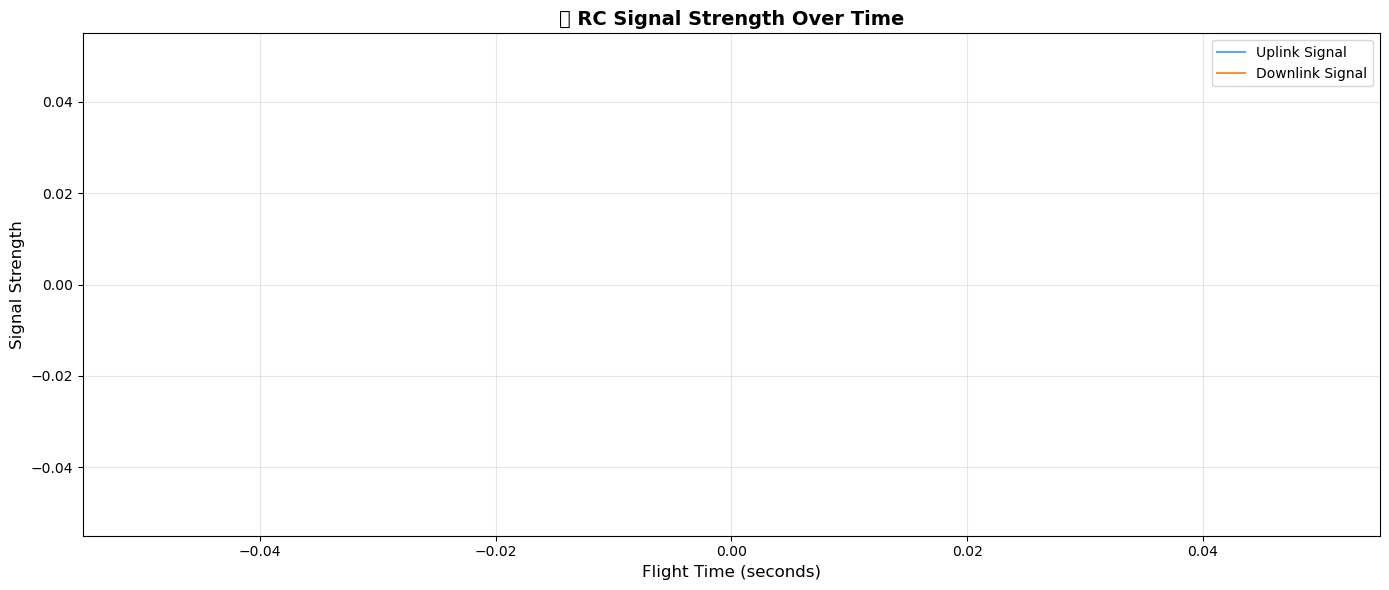

In [9]:
uplink = pd.to_numeric(df['RC.uplinkSignal'], errors='coerce')
downlink = pd.to_numeric(df['RC.downlinkSignal'], errors='coerce')

plt.figure(figsize=(14, 6))
plt.plot(df['OSD.flyTime [s]'], uplink, color='#3498DB', linewidth=1.5, label='Uplink Signal', alpha=0.8)
plt.plot(df['OSD.flyTime [s]'], downlink, color='#E67E22', linewidth=1.5, label='Downlink Signal', alpha=0.8)
plt.xlabel('Flight Time (seconds)', fontsize=12)
plt.ylabel('Signal Strength', fontsize=12)
plt.title('📶 RC Signal Strength Over Time', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Speed Components (X, Y, Z)
Shows the individual velocity components in 3D space.

/var/folders/0j/jrk4ghtd6wqfsm3km6pbbyn80000gn/T/ipykernel_92312/1857354178.py:27: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/calebstone/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


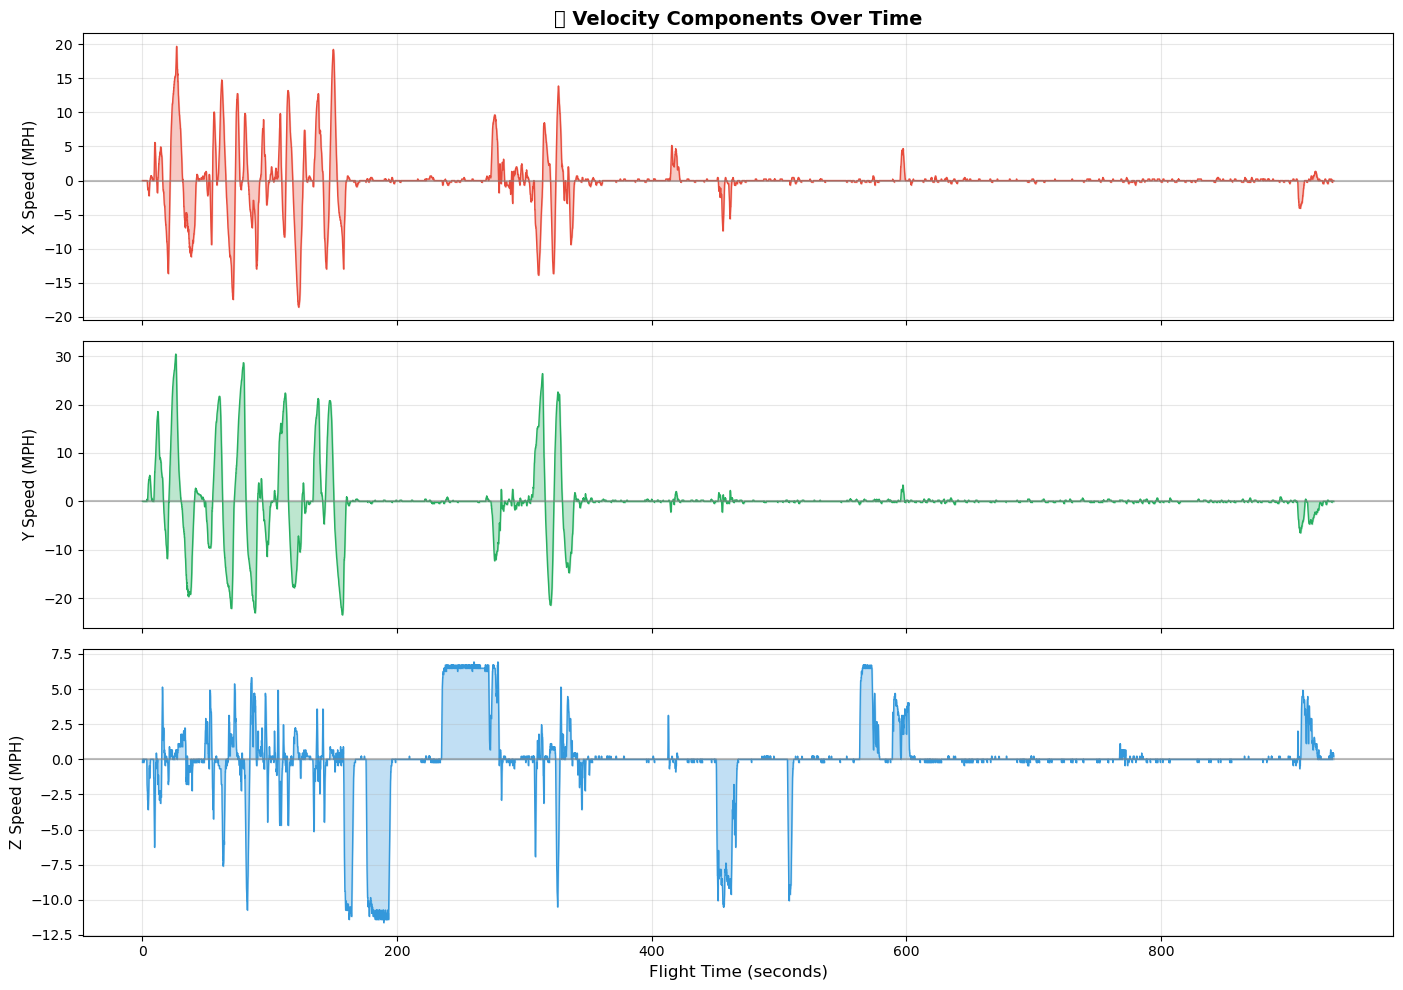

In [10]:
x_speed = pd.to_numeric(df['OSD.xSpeed [MPH]'], errors='coerce')
y_speed = pd.to_numeric(df['OSD.ySpeed [MPH]'], errors='coerce')
z_speed = pd.to_numeric(df['OSD.zSpeed [MPH]'], errors='coerce')

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

ax1.plot(df['OSD.flyTime [s]'], x_speed, color='#E74C3C', linewidth=1)
ax1.fill_between(df['OSD.flyTime [s]'], x_speed, alpha=0.3, color='#E74C3C')
ax1.set_ylabel('X Speed (MPH)', fontsize=11)
ax1.axhline(y=0, color='gray', linestyle='-', alpha=0.5)
ax1.grid(True, alpha=0.3)
ax1.set_title('🎯 Velocity Components Over Time', fontsize=14, fontweight='bold')

ax2.plot(df['OSD.flyTime [s]'], y_speed, color='#27AE60', linewidth=1)
ax2.fill_between(df['OSD.flyTime [s]'], y_speed, alpha=0.3, color='#27AE60')
ax2.set_ylabel('Y Speed (MPH)', fontsize=11)
ax2.axhline(y=0, color='gray', linestyle='-', alpha=0.5)
ax2.grid(True, alpha=0.3)

ax3.plot(df['OSD.flyTime [s]'], z_speed, color='#3498DB', linewidth=1)
ax3.fill_between(df['OSD.flyTime [s]'], z_speed, alpha=0.3, color='#3498DB')
ax3.set_xlabel('Flight Time (seconds)', fontsize=12)
ax3.set_ylabel('Z Speed (MPH)', fontsize=11)
ax3.axhline(y=0, color='gray', linestyle='-', alpha=0.5)
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Battery Voltage Over Time
Monitors the battery voltage throughout the flight.

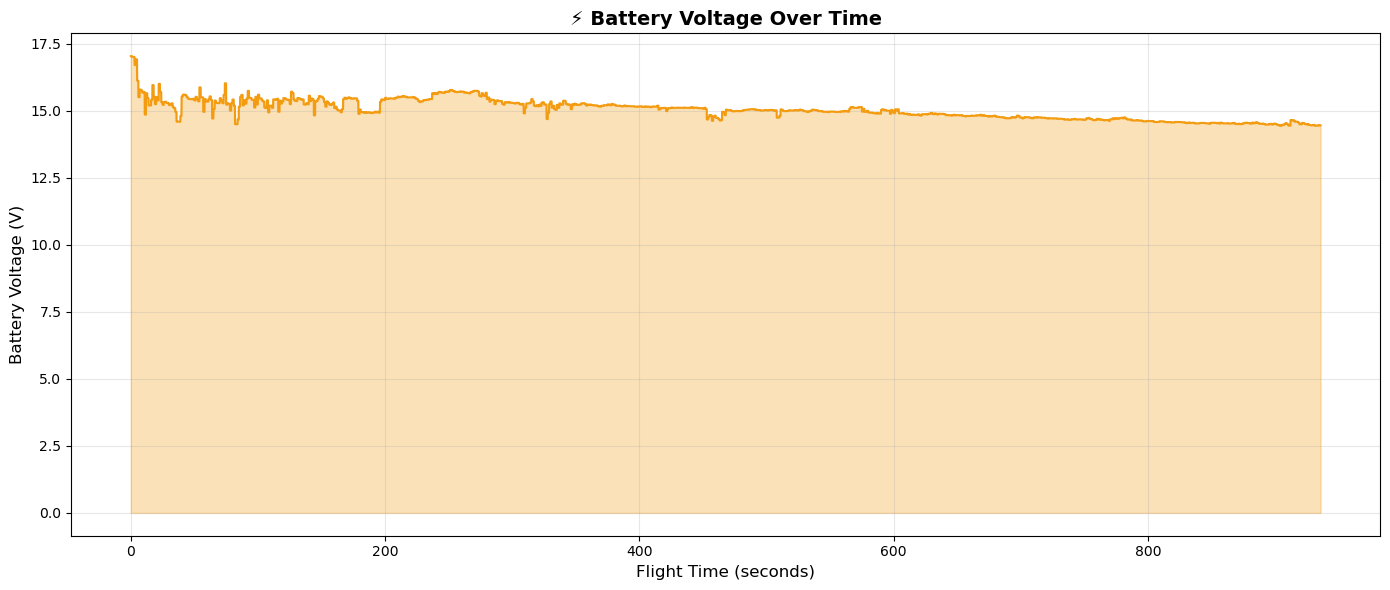

In [11]:
voltage = pd.to_numeric(df['BATTERY.voltage [V]'], errors='coerce')

plt.figure(figsize=(14, 6))
plt.plot(df['OSD.flyTime [s]'], voltage, color='#F39C12', linewidth=1.5)
plt.fill_between(df['OSD.flyTime [s]'], voltage, alpha=0.3, color='#F39C12')
plt.xlabel('Flight Time (seconds)', fontsize=12)
plt.ylabel('Battery Voltage (V)', fontsize=12)
plt.title('⚡ Battery Voltage Over Time', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Drone Pitch and Roll (Orientation)
Visualizes the drone's own orientation during flight.

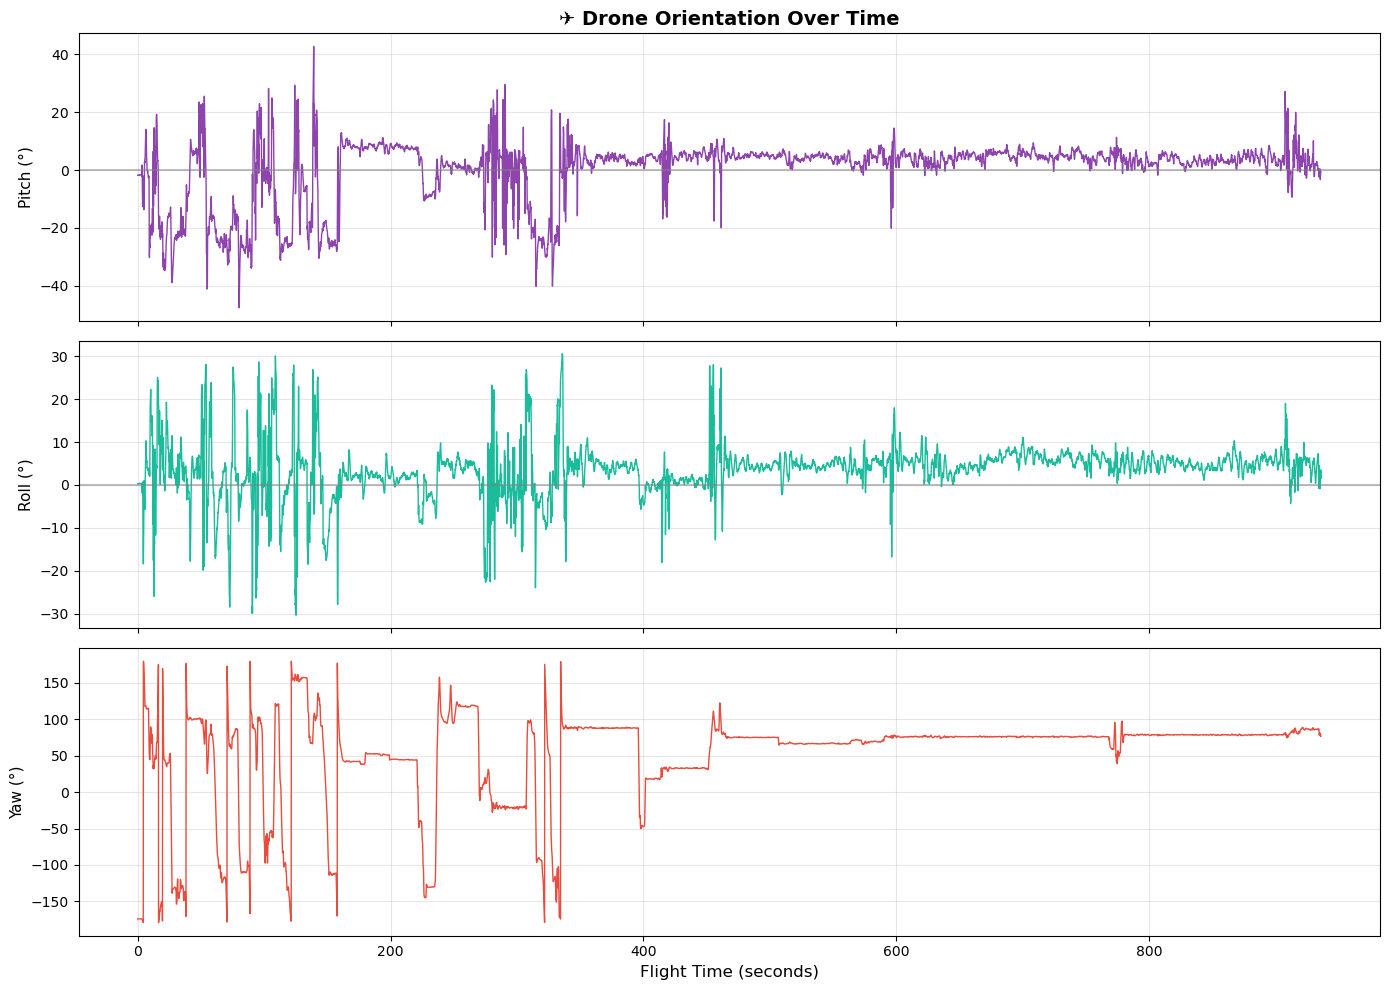

In [12]:
pitch = pd.to_numeric(df['OSD.pitch'], errors='coerce')
roll = pd.to_numeric(df['OSD.roll'], errors='coerce')
yaw = pd.to_numeric(df['OSD.yaw'], errors='coerce')

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

axes[0].plot(df['OSD.flyTime [s]'], pitch, color='#8E44AD', linewidth=1)
axes[0].set_ylabel('Pitch (°)', fontsize=11)
axes[0].axhline(y=0, color='gray', linestyle='-', alpha=0.5)
axes[0].grid(True, alpha=0.3)
axes[0].set_title('✈️ Drone Orientation Over Time', fontsize=14, fontweight='bold')

axes[1].plot(df['OSD.flyTime [s]'], roll, color='#1ABC9C', linewidth=1)
axes[1].set_ylabel('Roll (°)', fontsize=11)
axes[1].axhline(y=0, color='gray', linestyle='-', alpha=0.5)
axes[1].grid(True, alpha=0.3)

axes[2].plot(df['OSD.flyTime [s]'], yaw, color='#E74C3C', linewidth=1)
axes[2].set_xlabel('Flight Time (seconds)', fontsize=12)
axes[2].set_ylabel('Yaw (°)', fontsize=11)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 12. GPS Satellites Count Over Time
Shows the number of GPS satellites connected during the flight.

/var/folders/0j/jrk4ghtd6wqfsm3km6pbbyn80000gn/T/ipykernel_92312/2615020750.py:13: UserWarning: Glyph 128752 (\N{SATELLITE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/calebstone/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128752 (\N{SATELLITE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


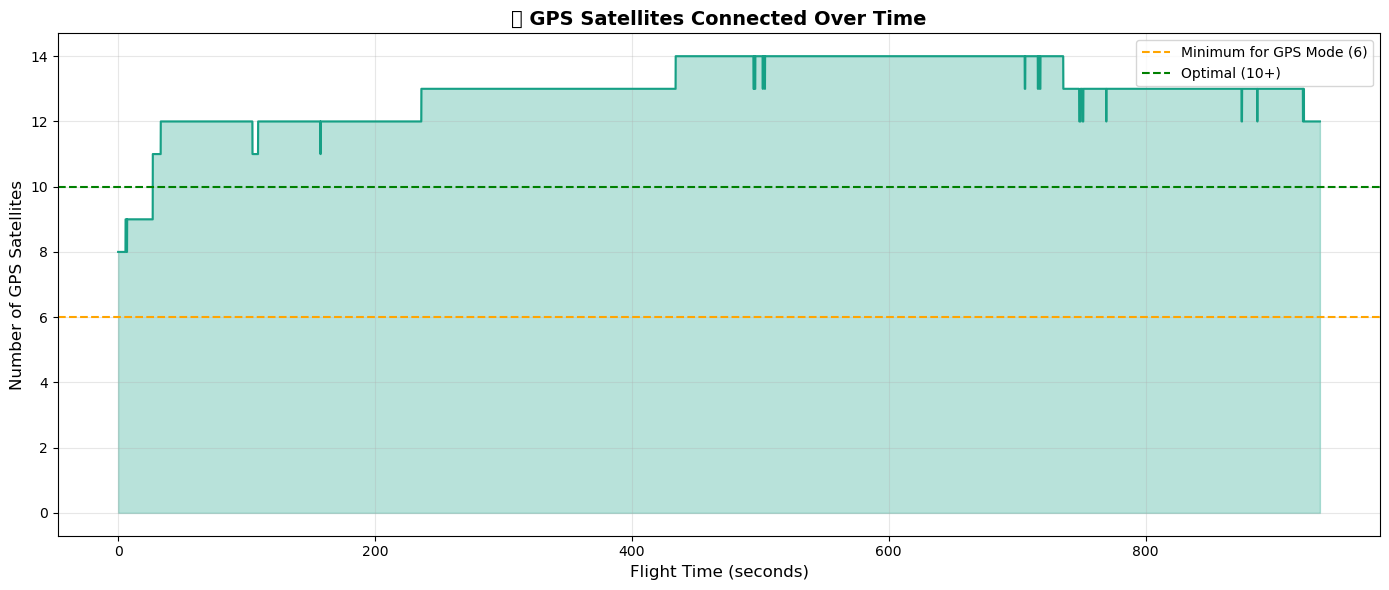

In [13]:
gps_num = pd.to_numeric(df['OSD.gpsNum'], errors='coerce')

plt.figure(figsize=(14, 6))
plt.plot(df['OSD.flyTime [s]'], gps_num, color='#16A085', linewidth=1.5, marker='', markersize=2)
plt.fill_between(df['OSD.flyTime [s]'], gps_num, alpha=0.3, color='#16A085')
plt.axhline(y=6, color='orange', linestyle='--', label='Minimum for GPS Mode (6)')
plt.axhline(y=10, color='green', linestyle='--', label='Optimal (10+)')
plt.xlabel('Flight Time (seconds)', fontsize=12)
plt.ylabel('Number of GPS Satellites', fontsize=12)
plt.title('🛰️ GPS Satellites Connected Over Time', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Summary Statistics

In [14]:
# Calculate some interesting statistics
print("=" * 50)
print("📊 FLIGHT SUMMARY STATISTICS")
print("=" * 50)

max_altitude = pd.to_numeric(df['OSD.height [ft]'], errors='coerce').max()
max_speed = pd.to_numeric(df['OSD.hSpeed [MPH]'], errors='coerce').max()
max_distance = pd.to_numeric(df['HOME.distance [ft]'], errors='coerce').max()
flight_time = df['OSD.flyTime [s]'].max()
total_mileage = pd.to_numeric(df['OSD.mileage [ft]'], errors='coerce').max()

print(f"\n🕐 Total Flight Time: {flight_time:.1f} seconds ({flight_time/60:.1f} minutes)")
print(f"📏 Total Distance Traveled: {total_mileage:.1f} feet ({total_mileage/5280:.2f} miles)")
print(f"🔝 Maximum Altitude: {max_altitude:.1f} feet")
print(f"⚡ Maximum Horizontal Speed: {max_speed:.1f} MPH")
print(f"🏠 Maximum Distance from Home: {max_distance:.1f} feet")

battery_start = pd.to_numeric(df['BATTERY.chargeLevel'], errors='coerce').dropna().iloc[0]
battery_end = pd.to_numeric(df['BATTERY.chargeLevel'], errors='coerce').dropna().iloc[-1]
print(f"\n🔋 Battery: {battery_start:.0f}% → {battery_end:.0f}% (Used: {battery_start-battery_end:.0f}%)")

avg_gps = pd.to_numeric(df['OSD.gpsNum'], errors='coerce').mean()
print(f"🛰️ Average GPS Satellites: {avg_gps:.1f}")

print("\n" + "=" * 50)

📊 FLIGHT SUMMARY STATISTICS

🕐 Total Flight Time: 935.7 seconds (15.6 minutes)
📏 Total Distance Traveled: 4461.7 feet (0.85 miles)
🔝 Maximum Altitude: 415.0 feet
⚡ Maximum Horizontal Speed: 34.6 MPH
🏠 Maximum Distance from Home: 317.9 feet

🔋 Battery: 96% → 33% (Used: 63%)
🛰️ Average GPS Satellites: 12.9

